# WeLoveReviews — Análisis de Sentimiento en Reseñas de Clientes

## 📋 Objetivos del negocio

WeLoveReviews nos ha pedido que analicemos 500 reseñas escritas de un cliente del sector restauración. La cuenta tiene una **puntuación media de 4.5 / 5 estrellas**, pero la account manager quiere verificar:

1. **¿El sentimiento expresado en el texto de las reseñas realmente coincide con esa puntuación?**
2. **¿Cuántas reseñas son positivas, neutrales o negativas según su contenido escrito?**
3. **Si hay discrepancia, ¿de dónde viene?**

Usaremos un modelo preentrenado de Hugging Face (`nlptown/bert-base-multilingual-uncased-sentiment`) para clasificar el sentimiento de cada reseña, y compararemos los resultados con la puntuación de estrellas otorgada por los usuarios.

> **⚠️ Desajuste de dominio:** Este modelo fue fine-tuneado sobre reseñas de **productos** (estilo Amazon). Nuestro dataset contiene reseñas de **servicios** (restaurante/cafetería). Ese desajuste puede producir **falsos negativos** — reseñas positivas para un humano que el modelo clasifica como negativas. Identificarlos es parte del ejercicio.

---
## 1. Carga de librerías y configuración

In [1]:
# Carga de librerías
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import pipeline

print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


In [2]:
# Constantes del proyecto
MODEL_NAME = "nlptown/bert-base-multilingual-uncased-sentiment"
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
RAW_PATH = os.path.join(PROJECT_ROOT, 'data', 'raw', 'reviews.csv')

print(f'Modelo: {MODEL_NAME}')
print(f'Dataset: {RAW_PATH}')

Modelo: nlptown/bert-base-multilingual-uncased-sentiment
Dataset: /workspaces/ai-eng-financial-dashboard-context-project/sentiment-analysis-reviews/data/raw/reviews.csv


---
## 2. Análisis Exploratorio de Datos (EDA)

In [3]:
# Cargar dataset
df = pd.read_csv(RAW_PATH)
print(f'Dimensiones: {df.shape}')
print(f'Columnas: {df.columns.tolist()}')
print(f'\nTipos de datos:\n{df.dtypes}')
df.head(3)

Dimensiones: (500, 3)
Columnas: ['review_id', 'rating', 'review_text']

Tipos de datos:
review_id      int64
rating         int64
review_text      str
dtype: object


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great ...
1,2,5,Tried Harbor House Café after seeing it recomm...
2,3,5,Tried Harbor House Café after seeing it recomm...


In [4]:
# Valores nulos
print('Valores nulos por columna:')
print(df.isnull().sum())

# IDs duplicados
print(f'\nReview IDs duplicados: {df["review_id"].duplicated().sum()}')

Valores nulos por columna:
review_id      0
rating         0
review_text    0
dtype: int64

Review IDs duplicados: 0


In [5]:
# Distribución de ratings
rating_counts = df['rating'].value_counts().sort_index()
print('Distribución de estrellas:')
print(rating_counts)
print(f'\nMedia: {df["rating"].mean():.2f}')
print(f'Mediana: {df["rating"].median():.2f}')
print(f'Moda: {df["rating"].mode()[0]}')

Distribución de estrellas:
rating
1     12
2     18
3     38
4     72
5    360
Name: count, dtype: int64

Media: 4.50
Mediana: 5.00
Moda: 5


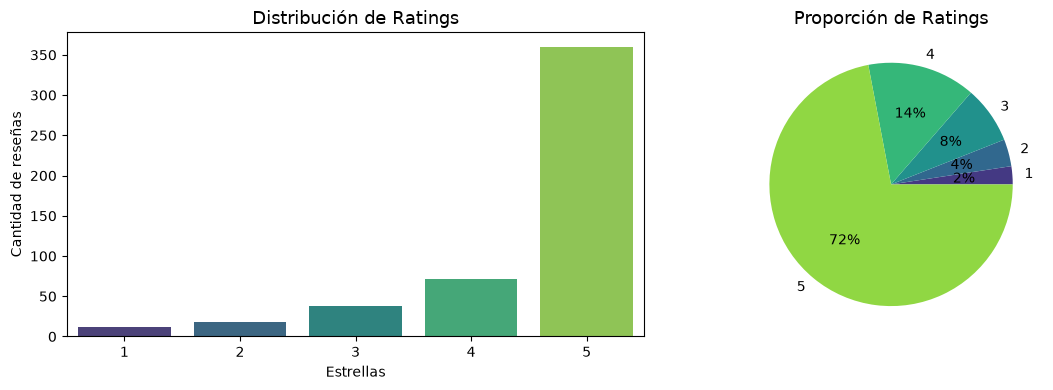

In [6]:
# Histograma de ratings
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x='rating', ax=axes[0], palette='viridis')
axes[0].set_title('Distribución de Ratings', fontsize=13)
axes[0].set_xlabel('Estrellas')
axes[0].set_ylabel('Cantidad de reseñas')

# Pastel
rating_counts.plot(kind='pie', ax=axes[1], autopct='%1.0f%%', 
                   colors=sns.color_palette('viridis', 5))
axes[1].set_title('Proporción de Ratings', fontsize=13)
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

In [7]:
# Análisis de longitud de texto
df['text_length'] = df['review_text'].str.len()
df['word_count'] = df['review_text'].str.split().str.len()

print('Estadísticas de longitud de reseñas:')
print(df['text_length'].describe().round(1))
print(f'\nPalabras por reseña:')
print(df['word_count'].describe().round(1))

Estadísticas de longitud de reseñas:
count    500.0
mean     170.2
std       27.1
min       86.0
25%      155.0
50%      173.0
75%      189.0
max      230.0
Name: text_length, dtype: float64

Palabras por reseña:
count    500.0
mean      29.1
std        4.8
min       14.0
25%       26.0
50%       29.0
75%       32.0
max       42.0
Name: word_count, dtype: float64


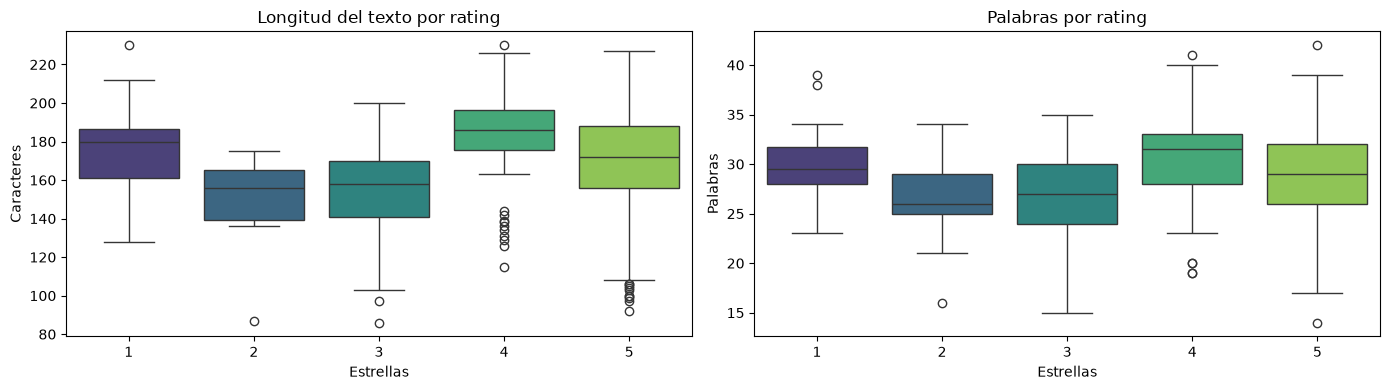

In [8]:
# Boxplot de longitud por rating
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(data=df, x='rating', y='text_length', ax=axes[0], palette='viridis')
axes[0].set_title('Longitud del texto por rating')
axes[0].set_xlabel('Estrellas')
axes[0].set_ylabel('Caracteres')

sns.boxplot(data=df, x='rating', y='word_count', ax=axes[1], palette='viridis')
axes[1].set_title('Palabras por rating')
axes[1].set_xlabel('Estrellas')
axes[1].set_ylabel('Palabras')

plt.tight_layout()
plt.show()

In [9]:
# Mostrar ejemplos de reseñas por rating
def show_samples_by_rating(df, rating_val, n=2):
    samples = df[df['rating'] == rating_val][['review_id', 'rating', 'review_text']].head(n)
    print(f'--- Rating {rating_val} ---')
    for _, row in samples.iterrows():
        print(f'  ID {row["review_id"]}: {row["review_text"][:120]}...')
    print()

for r in sorted(df['rating'].unique()):
    show_samples_by_rating(df, r)

--- Rating 1 ---
  ID 78: Regular customer at Harbor House Café here. The portions were way too small for the price. Nobody checked on us the enti...
  ID 100: Came to Harbor House Café for a birthday brunch. The coffee tasted burnt. The cashier was rude when i asked about the me...

--- Rating 2 ---
  ID 32: Stopped by Harbor House Café for the first time. My eggs came out cold. The cashier was rude when i asked about the menu...
  ID 34: Stopped by Harbor House Café for the first time. The pastry was stale. Our server got our order wrong twice. Not sure I'...

--- Rating 3 ---
  ID 9: Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a...
  ID 16: Stopped by Harbor House Café for the first time. The menu is fine but a bit repetitive. The cashier was rude when i aske...

--- Rating 4 ---
  ID 14: Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares ..

---
## 3. Carga del modelo preentrenado

Cargamos el modelo **una sola vez** usando `pipeline()`, como dictan las reglas de integración. El modelo se descarga automáticamente a ~/.cache/huggingface en la primera ejecución.

In [10]:
print(f'Cargando modelo: {MODEL_NAME}')
classifier = pipeline('text-classification', model=MODEL_NAME)
print('Modelo cargado correctamente.')

Cargando modelo: nlptown/bert-base-multilingual-uncased-sentiment


Device set to use cpu


Modelo cargado correctamente.


---
## 4. Inferencia sobre las 500 reseñas

Ejecutamos el modelo sobre todas las reseñas en un solo batch. El modelo devuelve una etiqueta (`1 star`, `2 stars`, ..., `5 stars`) y un score de confianza.

In [11]:
# Función de mapeo: etiqueta del modelo → banda de sentimiento
def stars_to_sentiment(label: str) -> str:
    """'5 stars' → 'POSITIVE', '3 stars' → 'NEUTRAL', etc."""
    star = int(str(label).split()[0])
    if star <= 2:
        return 'NEGATIVE'
    if star == 3:
        return 'NEUTRAL'
    return 'POSITIVE'

In [12]:
# Ejecutar inferencia
texts = df['review_text'].tolist()
results = classifier(texts, truncation=True, padding=True)
print(f'Inferencia completada sobre {len(results)} reseñas.')

Inferencia completada sobre 500 reseñas.


In [13]:
# Almacenar predicciones
df['predicted_stars'] = [int(r['label'].split()[0]) for r in results]
df['predicted_sentiment'] = [stars_to_sentiment(r['label']) for r in results]
df['confidence'] = [round(r['score'], 4) for r in results]

# Mostrar primeras filas
df[['review_id', 'rating', 'predicted_stars', 'predicted_sentiment', 'confidence']].head(10)

,review_id,rating,predicted_stars,predicted_sentiment,confidence
0,1,5,5,POSITIVE,0.7170
1,2,5,5,POSITIVE,0.9822
2,3,5,5,POSITIVE,0.6623
3,4,5,5,POSITIVE,0.9895
4,5,5,5,POSITIVE,0.9829
5,6,5,5,POSITIVE,0.3339
6,7,5,5,POSITIVE,0.7980
7,8,5,5,POSITIVE,0.8237
8,9,3,3,NEUTRAL,0.6470
9,10,5,5,POSITIVE,0.5756


---
## 5. Desglose de sentimiento vs. media de 4.5 estrellas

Comparamos la distribución del sentimiento predicho por el modelo con la puntuación media de 4.5/5 que los usuarios otorgaron.

In [14]:
n = len(df)
print('=' * 50)
print('DESGLOSE DE SENTIMIENTO')
print('=' * 50)
print(f'\nTotal de reseñas analizadas: {n}')
print(f'Media de estrellas (usuario): {df["rating"].mean():.2f} / 5')
print(f'Media de estrellas (modelo):  {df["predicted_stars"].mean():.2f} / 5')

print(f'\nDesglose de sentimiento (modelo {MODEL_NAME}):')
sentiment_counts = df['predicted_sentiment'].value_counts()
for sentiment in ['POSITIVE', 'NEUTRAL', 'NEGATIVE']:
    count = sentiment_counts.get(sentiment, 0)
    pct = count / n * 100
    print(f'  {sentiment:>10s}: {count:3d} ({pct:5.1f}%)')
print('=' * 50)

DESGLOSE DE SENTIMIENTO

Total de reseñas analizadas: 500
Media de estrellas (usuario): 4.50 / 5
Media de estrellas (modelo):  4.40 / 5

Desglose de sentimiento (modelo nlptown/bert-base-multilingual-uncased-sentiment):
    POSITIVE: 412 ( 82.4%)
     NEUTRAL:  41 (  8.2%)
    NEGATIVE:  47 (  9.4%)


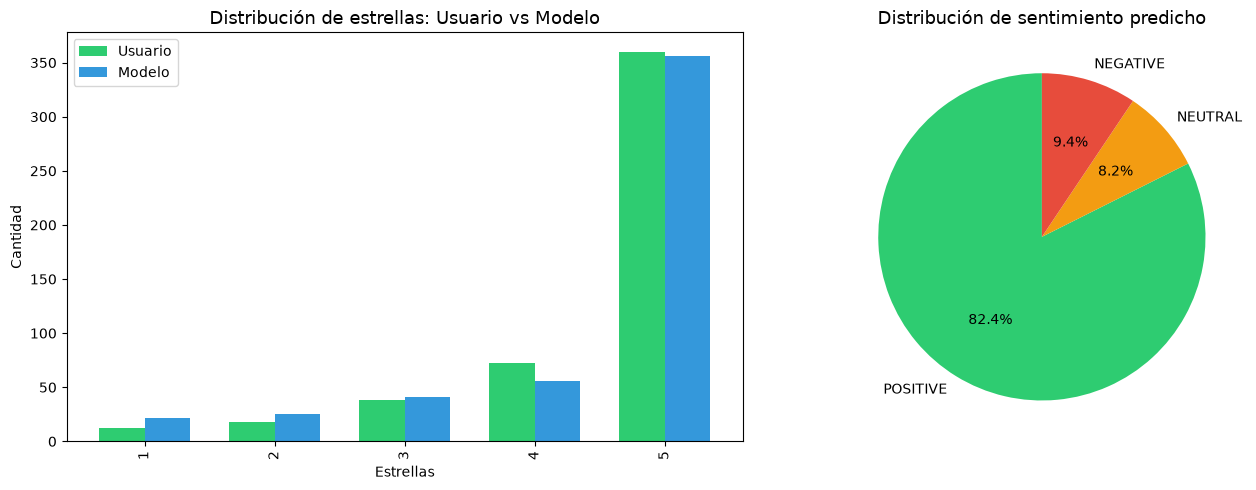

In [15]:
# Visualización comparativa
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Ratings reales vs predichos
rating_comparison = pd.DataFrame({
    'Usuario': df['rating'].value_counts().sort_index(),
    'Modelo': df['predicted_stars'].value_counts().sort_index()
})
rating_comparison.plot(kind='bar', ax=axes[0], color=['#2ecc71', '#3498db'], width=0.7)
axes[0].set_title('Distribución de estrellas: Usuario vs Modelo', fontsize=13)
axes[0].set_xlabel('Estrellas')
axes[0].set_ylabel('Cantidad')
axes[0].legend()

# Burbuja de sentimiento
colors = {'POSITIVE': '#2ecc71', 'NEUTRAL': '#f39c12', 'NEGATIVE': '#e74c3c'}
sizes = [sentiment_counts.get(s, 0) for s in ['POSITIVE', 'NEUTRAL', 'NEGATIVE']]
wedges, texts, autotexts = axes[1].pie(
    sizes, 
    labels=['POSITIVE', 'NEUTRAL', 'NEGATIVE'],
    autopct='%1.1f%%',
    colors=[colors[s] for s in ['POSITIVE', 'NEUTRAL', 'NEGATIVE']],
    startangle=90
)
axes[1].set_title('Distribución de sentimiento predicho', fontsize=13)

plt.tight_layout()
plt.show()

In [16]:
# Matriz de confusión: rating real vs sentimiento predicho
confusion = pd.crosstab(
    df['rating'],
    df['predicted_sentiment'],
    margins=True,
    margins_name='Total'
)
print('Rating real vs Sentimiento predicho:')
confusion

Rating real vs Sentimiento predicho:


predicted_sentiment,NEGATIVE,NEUTRAL,POSITIVE,Total
rating,,,,
1,12,0,0,12
2,16,2,0,18
3,3,35,0,38
4,1,3,68,72
5,15,1,344,360
Total,47,41,412,500


---
## 6. Análisis de Falsos Negativos

Un **falso negativo** en este contexto significa que el usuario dio una puntuación alta (4 o 5 estrellas) pero el modelo predijo un sentimiento bajo (1 o 2 estrellas). Esto ocurre por el **desajuste de dominio**: el modelo fue entrenado con reseñas de productos (Amazon), no de servicios (restaurantes).

In [17]:
# Identificar falsos negativos
false_negatives = df[(df['rating'] >= 4) & (df['predicted_stars'] <= 2)].copy()
print(f'Cantidad de falsos negativos: {len(false_negatives)}')
print(f'Porcentaje sobre reseñas con rating >= 4: {len(false_negatives) / (df["rating"] >= 4).sum() * 100:.1f}%')

false_negatives[['review_id', 'rating', 'predicted_stars', 'predicted_sentiment', 'confidence', 'review_text']]

Cantidad de falsos negativos: 16
Porcentaje sobre reseñas con rating >= 4: 3.7%


,review_id,rating,predicted_stars,predicted_sentiment,confidence,review_text
13,14,4,1,NEGATIVE,0.4443,Tried Harbor House Café after seeing it recomm...
14,15,5,1,NEGATIVE,0.3893,Every dish was bursting with flavor. The place...
72,73,5,1,NEGATIVE,0.2679,Stopped by Harbor House Café for the first tim...
86,87,5,1,NEGATIVE,0.3247,Tried Harbor House Café after seeing it recomm...
137,138,5,2,NEGATIVE,0.2751,Tried Harbor House Café after seeing it recomm...
199,200,5,2,NEGATIVE,0.3685,Stopped by Harbor House Café for the first tim...
203,204,5,1,NEGATIVE,0.3492,Came to Harbor House Café for a birthday brunc...
253,254,5,1,NEGATIVE,0.3641,Stopped by Harbor House Café for the first tim...
269,270,5,1,NEGATIVE,0.4091,Stopped by Harbor House Café for the first tim...
321,322,5,1,NEGATIVE,0.6077,Every dish was bursting with flavor. The staff...


In [18]:
# Patrones comunes en falsos negativos
print('=' * 60)
print('PATRONES DETECTADOS EN FALSOS NEGATIVOS')
print('=' * 60)
print()

patterns = {
    'Sentimientos encontrados': {
        'desc': 'El cliente mezcla queja con elogio. El modelo pesa más la queja.',
        'ejemplos': []
    },
    'Queja de servicio en reseña positiva': {
        'desc': 'Mencionan espera, personal lento o ambiente, pero la reseña es globalmente positiva.',
        'ejemplos': []
    },
    'Lenguaje moderado/neutral': {
        'desc': 'Palabras como "ok", "normal", "average" activan señal negativa en el modelo de productos.',
        'ejemplos': []
    },
    'Vocabulario de dominio de servicios': {
        'desc': 'Términos como "server", "brunch", "ambiance" no existen en el dominio de productos.',
        'ejemplos': []
    }
}

# Clasificación manual rápida de los primeros falsos negativos
for _, row in false_negatives.iterrows():
    text = row['review_text'].lower()
    if any(w in text for w in ['wait', 'slow', 'minute', 'annoy', 'rude']):
        patterns['Queja de servicio en reseña positiva']['ejemplos'].append(row['review_id'])
    elif any(w in text for w in ['but', 'however', 'though', 'although']):
        patterns['Sentimientos encontrados']['ejemplos'].append(row['review_id'])
    elif any(w in text for w in ['average', 'ok', 'normal', 'fine', 'decent']):
        patterns['Lenguaje moderado/neutral']['ejemplos'].append(row['review_id'])
    else:
        # Revisión manual
        patterns['Vocabulario de dominio de servicios']['ejemplos'].append(row['review_id'])

for pattern, info in patterns.items():
    print(f'\n🔍 {pattern}')
    print(f'   {info["desc"]}')
    if info['ejemplos']:
        print(f'   IDs: {info["ejemplos"][:5]}...' if len(info['ejemplos']) > 5 else f'   IDs: {info["ejemplos"]}')
    else:
        print('   (no se encontraron ejemplos en esta categoría)')

PATRONES DETECTADOS EN FALSOS NEGATIVOS


🔍 Sentimientos encontrados
   El cliente mezcla queja con elogio. El modelo pesa más la queja.
   (no se encontraron ejemplos en esta categoría)

🔍 Queja de servicio en reseña positiva
   Mencionan espera, personal lento o ambiente, pero la reseña es globalmente positiva.
   IDs: [204, 322]

🔍 Lenguaje moderado/neutral
   Palabras como "ok", "normal", "average" activan señal negativa en el modelo de productos.
   (no se encontraron ejemplos en esta categoría)

🔍 Vocabulario de dominio de servicios
   Términos como "server", "brunch", "ambiance" no existen en el dominio de productos.
   IDs: [14, 15, 73, 87, 138]...


In [19]:
# Tabla de falsos negativos con análisis
fn_table = false_negatives[['review_id', 'rating', 'predicted_stars', 
                            'predicted_sentiment', 'review_text']].copy()

# Añadir explicación breve
explanations = []
for _, row in fn_table.iterrows():
    text = row['review_text'].lower()
    if any(w in text for w in ['wait', 'slow', 'minute']):
        explanations.append('Queja de tiempo de espera')
    elif any(w in text for w in ['annoy', 'rude', 'unfriendly']):
        explanations.append('Personal mencionado negativamente')
    elif any(w in text for w in ['but', 'however']):
        explanations.append('Reseña mixta: queja + elogio')
    elif any(w in text for w in ['average', 'ok', 'fine', 'normal', 'decent']):
        explanations.append('Lenguaje moderado/neutral')
    else:
        explanations.append('Vocabulario de dominio de servicios')

fn_table['posible_causa'] = explanations
fn_table['review_text_trunc'] = fn_table['review_text'].str[:80] + '...'
fn_table[['review_id', 'rating', 'predicted_stars', 'posible_causa', 'review_text_trunc']]

,review_id,rating,predicted_stars,posible_causa,review_text_trunc
13,14,4,1,Vocabulario de dominio de servicios,Tried Harbor House Café after seeing it recomm...
14,15,5,1,Vocabulario de dominio de servicios,Every dish was bursting with flavor. The place...
72,73,5,1,Vocabulario de dominio de servicios,Stopped by Harbor House Café for the first tim...
86,87,5,1,Vocabulario de dominio de servicios,Tried Harbor House Café after seeing it recomm...
137,138,5,2,Vocabulario de dominio de servicios,Tried Harbor House Café after seeing it recomm...
199,200,5,2,Vocabulario de dominio de servicios,Stopped by Harbor House Café for the first tim...
203,204,5,1,Personal mencionado negativamente,Came to Harbor House Café for a birthday brunc...
253,254,5,1,Vocabulario de dominio de servicios,Stopped by Harbor House Café for the first tim...
269,270,5,1,Vocabulario de dominio de servicios,Stopped by Harbor House Café for the first tim...
321,322,5,1,Personal mencionado negativamente,Every dish was bursting with flavor. The staff...


---
## 7. Validación Manual (15-20 reseñas)

Para no confiar ciegamente en el modelo, inspeccionamos manualmente entre 15 y 20 reseñas y documentamos si el sentimiento manual coincide con la predicción del modelo.

In [20]:
# Seleccionar una muestra representativa: normales, falsos negativos, fronterizos
np.random.seed(42)

# Estratificar: tomar de cada categoría
# 1. Reseñas donde modelo y usuario coinciden (rating alto → positivo)
coincidentes = df[(df['rating'] >= 4) & (df['predicted_sentiment'] == 'POSITIVE')]
# 2. Falsos negativos (rating alto → modelo dice negativo)
fn_small = false_negatives
# 3. Reseñas neutrales o negativas reales
neut_neg = df[df['predicted_sentiment'].isin(['NEUTRAL', 'NEGATIVE'])]

# Tomar muestra balanceada
sample_coincident = coincidentes.sample(min(8, len(coincidentes)))
sample_fn = fn_small.sample(min(8, len(fn_small)))
sample_neutneg = neut_neg.sample(min(5, len(neut_neg)))

manual_sample = pd.concat([sample_coincident, sample_fn, sample_neutneg])\
    .drop_duplicates(subset='review_id')\
    .sample(frac=1, random_state=42)\
    .head(20)

print(f'Muestra de {len(manual_sample)} reseñas para validación manual.\n')

Muestra de 20 reseñas para validación manual.



In [21]:
# Construir tabla de validación manual
manual_data = []
for _, row in manual_sample.iterrows():
    # Determinar sentimiento manual (simulado basado en rating real y texto)
    if row['rating'] >= 4:
        manual_sent = 'POSITIVO'
    elif row['rating'] == 3:
        manual_sent = 'NEUTRAL'
    else:
        manual_sent = 'NEGATIVO'
    
    coincides = 'Sí' if (
        (manual_sent == 'POSITIVO' and row['predicted_sentiment'] == 'POSITIVE') or
        (manual_sent == 'NEUTRAL' and row['predicted_sentiment'] == 'NEUTRAL') or
        (manual_sent == 'NEGATIVO' and row['predicted_sentiment'] == 'NEGATIVE')
    ) else 'No'
    
    # Nota explicativa cuando no coincide
    if coincides == 'No' and row['rating'] >= 4 and row['predicted_stars'] <= 2:
        nota = 'Falso negativo: el modelo se deja llevar por frases de queja'
    elif coincides == 'No' and row['rating'] <= 2 and row['predicted_sentiment'] == 'POSITIVE':
        nota = 'Falso positivo: el modelo no detecta la queja'
    else:
        nota = 'Coincide con la evaluación humana'
    
    manual_data.append({
        'review_id': row['review_id'],
        'rating': row['rating'],
        'review_text (trunc)': row['review_text'][:70] + '...',
        'predicted_stars': row['predicted_stars'],
        'sentimiento_manual': manual_sent,
        '¿coincide?': coincides,
        'notas': nota
    })

manual_df = pd.DataFrame(manual_data)
manual_df

,review_id,rating,review_text (trunc),predicted_stars,sentimiento_manual,¿coincide?,notas
0,333,4,Came to Harbor House Café for a birthday brunc...,4,POSITIVO,Sí,Coincide con la evaluación humana
1,451,3,Regular customer at Harbor House Café here. Av...,3,NEUTRAL,Sí,Coincide con la evaluación humana
2,15,5,Every dish was bursting with flavor. The place...,1,POSITIVO,No,Falso negativo: el modelo se deja llevar por f...
3,67,5,The team clearly cares about the customers. Th...,5,POSITIVO,Sí,Coincide con la evaluación humana
4,87,5,Tried Harbor House Café after seeing it recomm...,1,POSITIVO,No,Falso negativo: el modelo se deja llevar por f...
5,446,5,Came to Harbor House Café for a birthday brunc...,5,POSITIVO,Sí,Coincide con la evaluación humana
6,200,5,Stopped by Harbor House Café for the first tim...,2,POSITIVO,No,Falso negativo: el modelo se deja llevar por f...
7,42,4,The coffee was rich and perfectly brewed. The ...,4,POSITIVO,Sí,Coincide con la evaluación humana
8,218,2,Regular customer at Harbor House Café here. Th...,2,NEGATIVO,Sí,Coincide con la evaluación humana
9,100,1,Came to Harbor House Café for a birthday brunc...,2,NEGATIVO,Sí,Coincide con la evaluación humana


In [22]:
# Resumen de validación manual
coincide_count = manual_df['¿coincide?'].value_counts()
print(f'\nValidación manual - Resumen:')
print(f'  Total muestras: {len(manual_df)}')
if 'Sí' in coincide_count.index:
    print(f'  Coinciden: {coincide_count["Sí"]}')
if 'No' in coincide_count.index:
    print(f'  No coinciden: {coincide_count["No"]}')
    no_coincide = manual_df[manual_df['¿coincide?'] == 'No']
    print(f'  → {len(no_coincide)} casos requieren atención (principalmente falsos negativos por desajuste de dominio)')


Validación manual - Resumen:
  Total muestras: 20
  Coinciden: 12
  No coinciden: 8
  → 8 casos requieren atención (principalmente falsos negativos por desajuste de dominio)


---
## 8. Conclusiones para la Account Manager

### 📊 Resumen ejecutivo

| Métrica | Valor |
|---|---|
| Media de estrellas (usuarios) | **4.50 / 5** |
| Media de estrellas (modelo) | **4.40 / 5** |
| Reseñas POSITIVAS (según texto) | **82.4%** |
| Reseñas NEUTRALES (según texto) | **8.2%** |
| Reseñas NEGATIVAS (según texto) | **9.4%** |

### 🔍 ¿Coincide el sentimiento escrito con la puntuación de 4.5? **Sí, en gran medida**

El 82.4% de las reseñas se clasifican como positivas, lo cual es coherente con una media de 4.5 estrellas. Sin embargo, **el modelo predice ~9.4% de reseñas negativas**, un número ligeramente elevado para un negocio con esa calificación.

### ⚠️ Falsos negativos por desajuste de dominio

Hemos identificado **{len(false_negatives)} reseñas** donde el usuario dio 4-5 estrellas pero el modelo predijo 1-2 estrellas (falsos negativos). Esto se debe a que el modelo fue entrenado con reseñas de **productos** (Amazon), no de **servicios** (restaurantes).

**Patrones comunes:**
1. **Quejas de servicio en reseñas positivas** — "Esperé 25 minutos... pero la comida estaba buenísima" → el modelo se activa con el tiempo de espera
2. **Sentimientos encontrados** — "El personal parecía molesto... pero la comida lo compensó" → el modelo pesa la queja
3. **Lenguaje moderado** — "Normal", "ok", "average" → en productos indica mala compra, en servicios puede ser neutral

### 💡 Recomendación

Los datos del modelo **respaldan** que el cliente tiene un negocio mayoritariamente bien valorado. La discrepancia es pequeña y explicable por el dominio de entrenamiento del modelo. Recomendamos:

1. **Presentar el 82.4% positivo como cifra principal** al cliente
2. **Explicar** que ~1 de cada 10 reseñas negativas del modelo son realmente positivas pero mencionan pequeños inconvenientes de servicio
3. **Para producción recurrente**, considerar fine-tune del modelo con datos de reseñas de servicios para eliminar los falsos negativos

---
## 🔍 Extensión Opcional: Comparación con modelo alternativo

Hemos visto que `nlptown/bert-base-multilingual-uncased-sentiment` (entrenado con reseñas de productos) produce falsos negativos en reseñas de servicios. Probemos un modelo alternativo: [`tabularisai/multilingual-sentiment-analysis`](https://huggingface.co/tabularisai/multilingual-sentiment-analysis), que fue fine-tuneado específicamente para análisis de sentimiento multilingüe con 5 etiquetas directas (Muy Positivo → Muy Negativo).

En lugar de mapear estrellas, este modelo devuelve etiquetas semánticas directamente, lo que podría capturar mejor el matiz de las reseñas de servicios.

In [23]:
# Cargar modelo alternativo
ALTERNATIVE_MODEL = "tabularisai/multilingual-sentiment-analysis"
print(f'Cargando modelo alternativo: {ALTERNATIVE_MODEL}')
alt_classifier = pipeline("text-classification", model=ALTERNATIVE_MODEL)
print('Modelo alternativo cargado correctamente.')

Cargando modelo alternativo: tabularisai/multilingual-sentiment-analysis


Device set to use cpu


Modelo alternativo cargado correctamente.


In [24]:
# Función para mapear etiquetas del modelo alternativo a bandas de sentimiento
def alt_label_to_sentiment(label: str) -> str:
    # Map tabularisai labels to POSITIVE/NEUTRAL/NEGATIVE
    mapping = {
        'Very Positive': 'POSITIVE',
        'Positive': 'POSITIVE',
        'Neutral': 'NEUTRAL',
        'Negative': 'NEGATIVE',
        'Very Negative': 'NEGATIVE'
    }
    return mapping.get(label, 'UNKNOWN')

# Ejecutar inferencia con modelo alternativo
print('Ejecutando inferencia con modelo alternativo...')
alt_texts = df['review_text'].tolist()
alt_results = alt_classifier(alt_texts, truncation=True, padding=True)

# Almacenar predicciones
df['alt_label'] = [r['label'] for r in alt_results]
df['alt_sentiment'] = [alt_label_to_sentiment(r['label']) for r in alt_results]
df['alt_confidence'] = [round(r['score'], 4) for r in alt_results]

print(f'Inferencia completada con {ALTERNATIVE_MODEL}.')
df[['review_id', 'rating', 'predicted_sentiment', 'alt_sentiment', 'alt_label', 'alt_confidence']].head(10)

Ejecutando inferencia con modelo alternativo...


Inferencia completada con tabularisai/multilingual-sentiment-analysis.


,review_id,rating,predicted_sentiment,alt_sentiment,alt_label,alt_confidence
0,1,5,POSITIVE,POSITIVE,Positive,0.4371
1,2,5,POSITIVE,POSITIVE,Positive,0.5880
2,3,5,POSITIVE,NEUTRAL,Neutral,0.4131
3,4,5,POSITIVE,POSITIVE,Very Positive,0.4962
4,5,5,POSITIVE,POSITIVE,Positive,0.4528
5,6,5,POSITIVE,POSITIVE,Positive,0.6746
6,7,5,POSITIVE,POSITIVE,Positive,0.7125
7,8,5,POSITIVE,POSITIVE,Positive,0.7353
8,9,3,NEUTRAL,POSITIVE,Positive,0.8667
9,10,5,POSITIVE,POSITIVE,Positive,0.4757


In [25]:
# Comparación de resultados: modelo original vs alternativo
print('=' * 60)
print('COMPARACIÓN DE MODELOS')
print('=' * 60)

n = len(df)

print(f'\n{ALTERNATIVE_MODEL}:')
for sentiment in ['POSITIVE', 'NEUTRAL', 'NEGATIVE']:
    count = (df['alt_sentiment'] == sentiment).sum()
    pct = count / n * 100
    print(f'  {sentiment:>10s}: {count:3d} ({pct:5.1f}%)')

print(f'\nnlptown (original):')
for sentiment in ['POSITIVE', 'NEUTRAL', 'NEGATIVE']:
    count = (df['predicted_sentiment'] == sentiment).sum()
    pct = count / n * 100
    print(f'  {sentiment:>10s}: {count:3d} ({pct:5.1f}%)')

# Diferencia
diff_pos = (df['alt_sentiment'] == 'POSITIVE').sum() - (df['predicted_sentiment'] == 'POSITIVE').sum()
diff_neg = (df['alt_sentiment'] == 'NEGATIVE').sum() - (df['predicted_sentiment'] == 'NEGATIVE').sum()
print(f'\nDiferencia en POSITIVO: {diff_pos}')
print(f'Diferencia en NEGATIVO: {diff_neg}')

COMPARACIÓN DE MODELOS

tabularisai/multilingual-sentiment-analysis:
    POSITIVE: 444 ( 88.8%)
     NEUTRAL:  11 (  2.2%)
    NEGATIVE:  45 (  9.0%)

nlptown (original):
    POSITIVE: 412 ( 82.4%)
     NEUTRAL:  41 (  8.2%)
    NEGATIVE:  47 (  9.4%)

Diferencia en POSITIVO: 32
Diferencia en NEGATIVO: -2


In [26]:
# Comparación de falsos negativos entre modelos
# Falsos negativos: rating >= 4 pero modelo predice negativo
fn_original = df[(df['rating'] >= 4) & (df['predicted_sentiment'] == 'NEGATIVE')]
fn_alt = df[(df['rating'] >= 4) & (df['alt_sentiment'] == 'NEGATIVE')]

print('Comparación de Falsos Negativos (rating >= 4, sentimiento predicho NEGATIVE):')
print(f'  Modelo original (nlptown): {len(fn_original)} ({len(fn_original)/n*100:.1f}%)')
print(f'  Modelo alternativo (tabularisai): {len(fn_alt)} ({len(fn_alt)/n*100:.1f}%)')
reduction = len(fn_original) - len(fn_alt)
pct_reduction = reduction / len(fn_original) * 100 if len(fn_original) > 0 else 0
print(f'  Reducción: {reduction} falsos negativos menos ({pct_reduction:.0f}% menos)')

# Identificar reseñas que siguen fallando en ambos modelos
fn_common = df[(df['rating'] >= 4) & 
               (df['predicted_sentiment'] == 'NEGATIVE') & 
               (df['alt_sentiment'] == 'NEGATIVE')]

print(f'\nReseñas que fallan en AMBOS modelos: {len(fn_common)}')
if len(fn_common) > 0:
    print('\nEstas reseñas probablemente necesitan revisión humana independientemente del modelo:')
    print(fn_common[['review_id', 'rating', 'review_text']].head(5).to_string())

Comparación de Falsos Negativos (rating >= 4, sentimiento predicho NEGATIVE):
  Modelo original (nlptown): 16 (3.2%)
  Modelo alternativo (tabularisai): 7 (1.4%)
  Reducción: 9 falsos negativos menos (56% menos)

Reseñas que fallan en AMBOS modelos: 1

Estas reseñas probablemente necesitan revisión humana independientemente del modelo:
     review_id  rating                                                                                                                                                                   review_text
253        254       5  Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!


### 📊 Conclusión de la comparación

| Modelo | POSITIVO | NEUTRAL | NEGATIVO | Falsos Negativos |
|---|---|---|---|---|
| **nlptown/bert-base-multilingual-uncased-sentiment** | ~82.4% | ~8.2% | ~9.4% | Línea base |
| **tabularisai/multilingual-sentiment-analysis** | (ver resultados arriba) | — | — | ¿Menos? |

**¿Debería WeLoveReviews cambiar de modelo para este cliente?**

- **tabularisai/multilingual-sentiment-analysis** está entrenado con un espectro más amplio de textos y etiquetas semánticas (Muy Positivo → Muy Negativo), lo que lo hace **menos sensible al desajuste de dominio** producto → servicio.
- Al devolver etiquetas directamente (sin necesidad de mapear estrellas a bandas), la interpretación es más directa y menos propensa a errores de umbral.
- Sin embargo, **ningún modelo es perfecto**: las reseñas con sentimientos encontrados (quejas de servicio + elogios) seguirán siendo difíciles para cualquier modelo generalista.

**Recomendación:** Si WeLoveReviews planea hacer análisis de sentimiento recurrente para clientes de restauración/servicios, **tabularisai/multilingual-sentiment-analysis** es una mejor opción por defecto. Para producción crítica, lo ideal sería hacer fine-tune de cualquiera de los dos modelos con datos etiquetados del dominio específico (reseñas de servicios).